### Week 10 notebook - K-Means: Elbow Method, Silhouette Score, Feature Scaling and Distance Metrics, Mod C Data Science Capstone Fall 2026
### By Shuqin Ouyang

# Overall notebook structure:

Breadth week, so only the four topics from the reading, each run on both datasets, plus one check against the failure label:
1. K-Means with the elbow method (WCSS) and the silhouette score (k = 2 to 10)
2. Feature scaling (the range of feature std, plus a scaled vs unscaled silhouette check on a 2,000-row sample)
3. Distance metrics
4. Check: failure rate in each cluster, on the training rows and on the unseen test rows
5. Conclusion and Summary

K-Means is fit on all the training rows of the Weeks 5 to 9 80/20 split. The failure label is never used to build the clusters.

# Student dataset analysis starts here:

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score

In [2]:
KS = range(2, 11)    # numbers of clusters tried

Helper function (used for both datasets):

In [3]:
def k_table(Z):
    # K-Means for each k: the WCSS (elbow) and the silhouette judged with three distance formulas
    rows = []
    for k in KS:
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
        rows.append({'k': k, 'WCSS': km.inertia_,
                     'silhouette euclidean': silhouette_score(Z, km.labels_),
                     'silhouette manhattan': silhouette_score(Z, km.labels_, metric='manhattan'),
                     'silhouette cosine': silhouette_score(Z, km.labels_, metric='cosine')})
    return pd.DataFrame(rows).set_index('k')

Dataset 1 background quick overview:

The dataset 1 used is the Taiwanese Bankruptcy Prediction dataset from UCI, link as https://archive.ics.uci.edu/dataset/572/taiwanese+bankruptcy+prediction.
It contains company financial indicators and a binary outcome for bankruptcy.

In [4]:
# install uci package so can load the data using package
# install once in terminal or notebook

!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# load dataset from UCI repository using dataset id
data_bankruptcy = fetch_ucirepo(id=572)

df_bankruptcy = pd.concat(
    [data_bankruptcy.data.features.copy(),
     data_bankruptcy.data.targets.copy()],
    axis=1
)

# remove leading/trailing spaces from column names once, here
df_bankruptcy.columns = df_bankruptcy.columns.str.strip()

df_bankruptcy.head()

'pip' is not recognized as an internal or external command,
operable program or batch file.


,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Continuous interest rate (after tax),...,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability,Bankrupt?
0,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,0.780985,...,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469,1
1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,0.781506,...,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794,1
2,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,0.780284,...,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474,1
3,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,0.781241,...,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982,1
4,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,0.781550,...,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490,1


Student markdown:

Dataset 1 is the Taiwanese bankruptcy data: 6,819 companies described by 95 financial ratios, of which about 3.2% went bankrupt. All features are numeric and none are missing.

In [5]:
X_train_bankrupt, X_test_bankrupt, y_train_bankrupt, y_test_bankrupt = train_test_split(df_bankruptcy.drop(columns='Bankrupt?'), df_bankruptcy['Bankrupt?'], test_size=0.2, stratify=df_bankruptcy['Bankrupt?'], random_state=42)    # same split as Weeks 5, 6, 8 and 9
scaler_bankrupt = StandardScaler().fit(X_train_bankrupt)
Z_bankrupt = scaler_bankrupt.transform(X_train_bankrupt)    # scaled training rows. K-Means never sees the target

Topic 1: K-Means with the elbow method and the silhouette score, on the scaled training rows. K-Means picks k centers, assigns each row to its nearest center, moves each center to the average of its rows, and repeats. WCSS (within-cluster sum of squares) is the total squared distance from the rows to their own center. It always falls as k grows, so the elbow is where it stops falling much. The silhouette compares a row's distance to its own cluster with its distance to the nearest other cluster, so a higher silhouette means cleaner clusters.

          WCSS  silhouette euclidean  silhouette manhattan  silhouette cosine
k                                                                            
2   478976.203                 0.108                 0.158              0.211
3   445710.242                 0.111                 0.160              0.128
4   430255.165                 0.108                 0.137              0.096
5   415765.137                 0.113                 0.139              0.082
6   393929.117                 0.110                 0.137              0.056
7   382578.678                 0.069                 0.110              0.081
8   368239.110                 0.068                 0.106              0.048
9   361897.153                 0.055                 0.098              0.025
10  351222.057                 0.055                 0.098              0.024


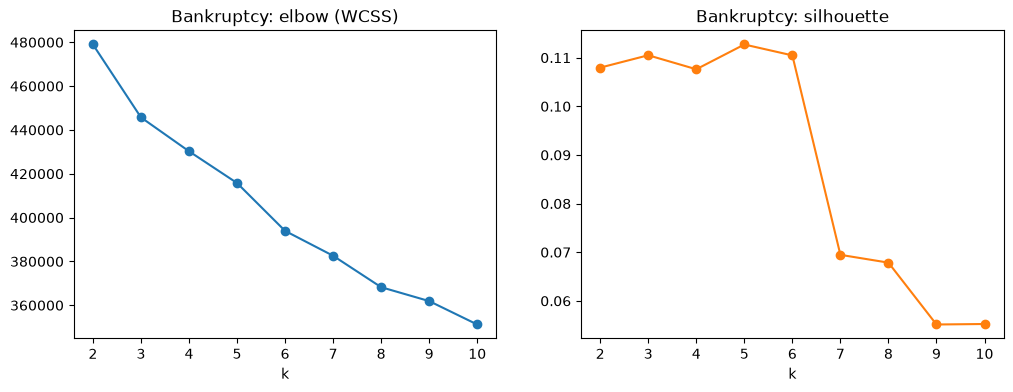

In [6]:
table_bankrupt = k_table(Z_bankrupt)
print(table_bankrupt.round(3))
table_bankrupt[['WCSS', 'silhouette euclidean']].plot(subplots=True, layout=(1, 2), figsize=(12, 4), marker='o', legend=False, title=['Bankruptcy: elbow (WCSS)', 'Bankruptcy: silhouette'])
plt.show()

Student markdown:

For bankruptcy, WCSS falls steadily as k grows and there is no clear bend, so the elbow does not point to a k. The silhouette is low and flat, about 0.11 for k = 2 to 6 and lower after that. The best Euclidean silhouette is k = 5 (0.113), but k = 3 scores almost the same (0.111), so k = 2 to 6 is close to a tie. A silhouette near 0.1 means the clusters overlap a lot, so the structure is weak. That is plausible with 95 financial ratios, since companies can be grouped in many different ways and no single k stands out. I use k = 5 because it has the highest silhouette, and the check at the end shows what that k contains.

Topic 2: feature scaling. K-Means and the silhouette depend on distances, so a column with a huge std would dominate them. Below are the best k from the full run, the range of feature std (a min of 0 is a constant column), and the silhouette by k on a random 2,000-row sample, scaled against unscaled (a sample, because the silhouette is slow on all rows). A higher unscaled score does not mean better clusters, since the huge columns inflate it. So the check shows whether scaling changes the result, not which result is right.

In [7]:
best_k_bankrupt = table_bankrupt['silhouette euclidean'].idxmax()
print("best k:", best_k_bankrupt)
print(X_train_bankrupt.std().agg(['min', 'max']))    # range of feature std (a min of 0 is a constant column)
print("silhouette by k, scaled vs unscaled, on a 2,000-row sample")
sample_bankrupt = X_train_bankrupt.sample(2000, random_state=42)
compare_bankrupt = pd.DataFrame({'scaled': k_table(StandardScaler().fit_transform(sample_bankrupt))['silhouette euclidean'],
                                 'unscaled': k_table(sample_bankrupt)['silhouette euclidean']})
print(compare_bankrupt.round(3))
print("best k:", compare_bankrupt.idxmax().to_dict())

best k: 5
min    0.000000e+00
max    3.387366e+09
dtype: float64
silhouette by k, scaled vs unscaled, on a 2,000-row sample
    scaled  unscaled
k                   
2    0.909     0.226
3    0.112     0.195
4    0.117     0.198
5    0.084     0.210
6    0.093     0.215
7    0.071     0.219
8    0.068     0.220
9    0.067     0.228
10   0.070     0.229
best k: {'scaled': 2, 'unscaled': 10}


Student markdown:

What the data shows: the feature std ranges from 0 (a constant column) to 3.39 billion, so unscaled, a few huge columns would decide the distances. On the 2,000-row sample, scaling changes the result a lot. Scaled, the silhouette is low for most k (0.07 to 0.12 from k = 3), with one very high value at k = 2 (0.909) that I did not investigate and that is probably a tiny group of extreme rows. Unscaled, it stays around 0.2 at every k and is best at k = 10 (0.229). So the best k is 2 scaled and 10 unscaled.

What it means: scaling matters for bankruptcy, because it changes which k wins. The unscaled scores are higher, but the huge columns inflate them, so I do not read them as better clusters, and the silhouette alone cannot prove that scaling helps. I use scaled data because otherwise a few columns decide the groups, as in Week 8. The sample's best k (2) also differs from the full-data best k (5), so the sample is only a rough guide. At k = 5 in the full run, two of the five clusters are single companies (rows (train) = 1 in the check below).

Topic 3: distance metrics. K-Means itself is always Euclidean, because the average of the rows is the point that minimizes the sum of squared Euclidean distances. The same scaled clusters are judged with Manhattan and cosine distance, to see whether the best k depends on how "close" is measured.

In [8]:
silhouettes_bankrupt = table_bankrupt.filter(like='silhouette')
print(silhouettes_bankrupt.round(3))
print(silhouettes_bankrupt.idxmax())    # best k for each distance formula

    silhouette euclidean  silhouette manhattan  silhouette cosine
k                                                                
2                  0.108                 0.158              0.211
3                  0.111                 0.160              0.128
4                  0.108                 0.137              0.096
5                  0.113                 0.139              0.082
6                  0.110                 0.137              0.056
7                  0.069                 0.110              0.081
8                  0.068                 0.106              0.048
9                  0.055                 0.098              0.025
10                 0.055                 0.098              0.024
silhouette euclidean    5
silhouette manhattan    3
silhouette cosine       2
dtype: int64


Student markdown:

The three distance formulas pick different best k for bankruptcy: Euclidean k = 5 (0.113), Manhattan k = 3 (0.160) and cosine k = 2 (0.211). So the best k is not stable here, which fits the weak structure seen above. The silhouette level also depends on the formula (Manhattan is higher than Euclidean at every k, and cosine falls fastest as k grows), so scores should only be compared within one formula.

Check against the failure label. K-Means does not predict failure, so instead of F1 the check is the failure rate in each cluster. K-Means is fit on the training rows at the best k, then the unseen test rows are assigned to the nearest center. A cluster far above the overall failure rate groups riskier rows, and a similar test rate means the pattern holds on rows K-Means never saw.

In [9]:
km_bankrupt = KMeans(n_clusters=best_k_bankrupt, n_init=10, random_state=42).fit(Z_bankrupt)
labels_test_bankrupt = km_bankrupt.predict(scaler_bankrupt.transform(X_test_bankrupt))
print("overall failure rate: train", round(y_train_bankrupt.mean(), 3), "| test", round(y_test_bankrupt.mean(), 3))
print(pd.DataFrame({'rows (train)': pd.Series(km_bankrupt.labels_).value_counts(),
                    'failure rate (train)': y_train_bankrupt.groupby(km_bankrupt.labels_).mean(),
                    'failure rate (test)': y_test_bankrupt.groupby(labels_test_bankrupt).mean(),
                    'failures (test)': y_test_bankrupt.groupby(labels_test_bankrupt).sum()}).round(3).rename_axis('cluster'))

overall failure rate: train 0.032 | test 0.032
         rows (train)  failure rate (train)  failure rate (test)  \
cluster                                                            
0                1003                 0.000                0.000   
1                1343                 0.115                0.124   
2                3107                 0.007                0.008   
3                   1                 0.000                  NaN   
4                   1                 0.000                  NaN   

         failures (test)  
cluster                   
0                    0.0  
1                   38.0  
2                    6.0  
3                    NaN  
4                    NaN  


Student markdown:

One bankruptcy cluster of 1,343 training rows has a failure rate of 0.115 in training and 0.124 in the unseen test rows, against an overall rate of 0.032, so about 3.6 times higher in training. It holds 38 of the 44 test failures. The largest cluster (3,107 rows) is very safe (0.007), the 1,003-row cluster has no failures, and the two single-row clusters have none and no test rows (their test rate is NaN because there is nothing to divide). So K-Means, which never saw the label, still found a group with much higher failure, and it holds on unseen rows. The test rate rests on 38 failures, so it is indicative, not precise.

Dataset 2 background quick overview:

The dataset 2 used is the Default of Credit Card Clients dataset from UCI, link as https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients.

It contains demographic information, credit limits, repayment history, bill statements, and previous payment records for Taiwanese credit card clients, along with a binary outcome indicating whether the client defaulted on the next payment.

In [10]:
# UCI dataset already decides features and targets already, but still need to look into details / verify to make sure all ok
data_credit = fetch_ucirepo(id=350)

df_credit = pd.concat(
    [data_credit.data.features.copy(),
     data_credit.data.targets.copy()],
    axis=1
)

df_credit.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [11]:
# columns rename for easier reading

df_credit = df_credit.rename(columns={

    "Y": "default_next_month",

    "X1": "credit_limit",
    "X2": "gender",
    "X3": "education",
    "X4": "marital_status",
    "X5": "age",

    "X6": "repay_2005_sep",
    "X7": "repay_2005_aug",
    "X8": "repay_2005_jul",
    "X9": "repay_2005_jun",
    "X10": "repay_2005_may",
    "X11": "repay_2005_apr",

    "X12": "bill_2005_sep",
    "X13": "bill_2005_aug",
    "X14": "bill_2005_jul",
    "X15": "bill_2005_jun",
    "X16": "bill_2005_may",
    "X17": "bill_2005_apr",

    "X18": "pay_2005_sep",
    "X19": "pay_2005_aug",
    "X20": "pay_2005_jul",
    "X21": "pay_2005_jun",
    "X22": "pay_2005_may",
    "X23": "pay_2005_apr"
})

df_credit.head()

,credit_limit,gender,education,marital_status,age,repay_2005_sep,repay_2005_aug,repay_2005_jul,repay_2005_jun,repay_2005_may,...,bill_2005_jun,bill_2005_may,bill_2005_apr,pay_2005_sep,pay_2005_aug,pay_2005_jul,pay_2005_jun,pay_2005_may,pay_2005_apr,default_next_month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


Student markdown:

Dataset 2 is the credit card default data: 30,000 clients described by 23 features (credit limit, demographics, six months of repayment status, bill amounts and payments), of which about 22% default next month. No values are missing.

In [12]:
X_train_credit, X_test_credit, y_train_credit, y_test_credit = train_test_split(df_credit.drop(columns='default_next_month'), df_credit['default_next_month'], test_size=0.2, stratify=df_credit['default_next_month'], random_state=42)    # same split as Weeks 5, 6, 8 and 9
scaler_credit = StandardScaler().fit(X_train_credit)
Z_credit = scaler_credit.transform(X_train_credit)    # scaled training rows. K-Means never sees the target

Topic 1 for credit card: the same K-Means, WCSS elbow and silhouette as for bankruptcy, on the scaled training rows.

          WCSS  silhouette euclidean  silhouette manhattan  silhouette cosine
k                                                                            
2   454676.048                 0.345                 0.395              0.233
3   390185.102                 0.185                 0.274              0.257
4   366233.367                 0.163                 0.256              0.175
5   347204.470                 0.156                 0.240              0.111
6   330114.199                 0.165                 0.243              0.097
7   316831.634                 0.143                 0.187              0.133
8   305439.305                 0.145                 0.187              0.131
9   295527.321                 0.143                 0.185              0.129
10  288210.151                 0.129                 0.154              0.070


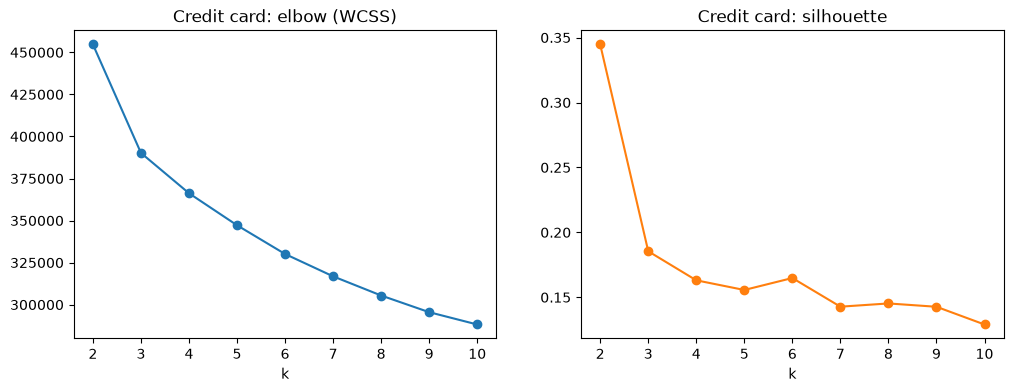

In [13]:
table_credit = k_table(Z_credit)
print(table_credit.round(3))
table_credit[['WCSS', 'silhouette euclidean']].plot(subplots=True, layout=(1, 2), figsize=(12, 4), marker='o', legend=False, title=['Credit card: elbow (WCSS)', 'Credit card: silhouette'])
plt.show()

Student markdown:

For credit card, WCSS drops most from k = 2 to k = 3 and more slowly after that, so the elbow bends around k = 3. The silhouette is much clearer than for bankruptcy: k = 2 scores 0.345, then it drops to 0.185 at k = 3 and 0.129 to 0.165 for larger k. The elbow and the silhouette are close but not identical (the plot starts at k = 2, so a bend between k = 1 and 2 cannot be seen). I use k = 2, the highest silhouette. I had expected more clusters here because of the many repayment columns, but the data prefers a simple two-way split.

Topic 2 for credit card: the same checks as for bankruptcy.

In [14]:
best_k_credit = table_credit['silhouette euclidean'].idxmax()
print("best k:", best_k_credit)
print(X_train_credit.std().agg(['min', 'max']))    # range of feature std (a min of 0 is a constant column)
print("silhouette by k, scaled vs unscaled, on a 2,000-row sample")
sample_credit = X_train_credit.sample(2000, random_state=42)
compare_credit = pd.DataFrame({'scaled': k_table(StandardScaler().fit_transform(sample_credit))['silhouette euclidean'],
                               'unscaled': k_table(sample_credit)['silhouette euclidean']})
print(compare_credit.round(3))
print("best k:", compare_credit.idxmax().to_dict())

best k: 2
min         0.488915
max    129511.313151
dtype: float64
silhouette by k, scaled vs unscaled, on a 2,000-row sample
    scaled  unscaled
k                   
2    0.341     0.543
3    0.180     0.475
4    0.154     0.450
5    0.167     0.412
6    0.166     0.418
7    0.171     0.418
8    0.137     0.392
9    0.135     0.347
10   0.136     0.345
best k: {'scaled': 2, 'unscaled': 2}


Student markdown:

What the data shows: the feature std ranges from 0.489 to 129,511, a gap of about 265,000 times. On the 2,000-row sample, the scaled silhouette is 0.341 at k = 2 and then 0.14 to 0.18, while the unscaled silhouette is higher at every k (0.543 at k = 2). The best k is 2 either way.

What it means: for credit card, scaling does not change the choice of k, so it matters less here than for bankruptcy. A possible reason is that the largest std is much smaller (129,511 against 3.39 billion), but I did not test that. The higher unscaled scores are again inflated by the large-valued columns. I still use scaled data for the same reason as before, and the sample agrees with the full-data best k of 2 (0.345).

Topic 3 for credit card: the same comparison as for bankruptcy.

In [15]:
silhouettes_credit = table_credit.filter(like='silhouette')
print(silhouettes_credit.round(3))
print(silhouettes_credit.idxmax())    # best k for each distance formula

    silhouette euclidean  silhouette manhattan  silhouette cosine
k                                                                
2                  0.345                 0.395              0.233
3                  0.185                 0.274              0.257
4                  0.163                 0.256              0.175
5                  0.156                 0.240              0.111
6                  0.165                 0.243              0.097
7                  0.143                 0.187              0.133
8                  0.145                 0.187              0.131
9                  0.143                 0.185              0.129
10                 0.129                 0.154              0.070
silhouette euclidean    2
silhouette manhattan    2
silhouette cosine       3
dtype: int64


Student markdown:

Euclidean and Manhattan both pick k = 2 (0.345 and 0.395), and cosine picks k = 3 (0.257, with 0.233 at k = 2). So the best k mostly holds across the three formulas for credit card, unlike bankruptcy, which I read as a more stable pattern. As before, the silhouette level depends on the formula, so scores should only be compared within one formula.

Check against the failure label for credit card: the same steps as for bankruptcy.

In [16]:
km_credit = KMeans(n_clusters=best_k_credit, n_init=10, random_state=42).fit(Z_credit)
labels_test_credit = km_credit.predict(scaler_credit.transform(X_test_credit))
print("overall failure rate: train", round(y_train_credit.mean(), 3), "| test", round(y_test_credit.mean(), 3))
print(pd.DataFrame({'rows (train)': pd.Series(km_credit.labels_).value_counts(),
                    'failure rate (train)': y_train_credit.groupby(km_credit.labels_).mean(),
                    'failure rate (test)': y_test_credit.groupby(labels_test_credit).mean(),
                    'failures (test)': y_test_credit.groupby(labels_test_credit).sum()}).round(3).rename_axis('cluster'))

overall failure rate: train 0.221 | test 0.221
         rows (train)  failure rate (train)  failure rate (test)  \
cluster                                                            
0                3698                 0.207                0.233   
1               20302                 0.224                0.219   

         failures (test)  
cluster                   
0                    223  
1                   1104  


Student markdown:

The two credit card clusters have 3,698 and 20,302 training rows, and their failure rates (0.207 and 0.224 in training, 0.233 and 0.219 in test) are all close to the overall 0.221, so neither cluster is clearly riskier. The test rates rest on 223 and 1,104 failures, so they are fairly reliable. So the clearest clusters in this notebook (silhouette 0.345) do not separate defaults: clear structure is not the same as risk-relevant structure.

Student markdown:

Conclusion:

**Overfitting:** For K-Means, overfitting would mean too many clusters, down to one cluster per row. I did not compare training and test scores (K-Means could be scored on both, for example the silhouette on the test rows), so I did not measure overfitting directly. Instead I watched for it and limited it another way: I did not choose k from WCSS (within-cluster sum of squares), which always falls as k grows, so the largest k would always win. I read the elbow chart and used the silhouette within k = 2 to 10 instead. This has a limit too: for bankruptcy I took k = 5, the highest silhouette, although k = 3 scores almost the same (0.111), so a smaller k would be just as defensible. The checks I did run measure stability, not overfitting. The best k holds across distance formulas for credit card (k = 2 under Euclidean and Manhattan, 3 under cosine) but not for bankruptcy (5, 3 and 2). On unseen test rows, the bankruptcy risky cluster holds (0.115 in training, 0.124 in test), and no credit card cluster differs from the overall rate.

**Metrics and results:** k was the only setting I tuned (n_init = 10 and random_state = 42 stayed fixed). I choose k by the highest Euclidean silhouette from 2 to 10, read the WCSS elbow as a second view, and check the clusters with the failure rate in each one, because K-Means does not predict failure, so F1 is not its score. K-Means uses Euclidean distance because the average of the rows minimizes the sum of squared Euclidean distances. The chosen k is 5 for bankruptcy (silhouette 0.113, low and flat) and 2 for credit card (silhouette 0.345). Silhouette scores should only be compared within one distance formula.

**Expected vs. unexpected:**
- Expected: scaling to be needed given the huge range of feature std; unsupervised groups that separate high-risk from low-risk rows; and more clusters for credit card, because it has many repayment columns.
- Unexpected, credit card: it settled on k = 2 and looked steadier, with the same best k under two distance formulas and with or without scaling.
- Unexpected, bankruptcy: no clear elbow, which makes sense with 95 ratios that can be grouped in many ways, and a best k that moves with the distance formula and with scaling.
- Unexpected, failure rates: bankruptcy has one cluster at about 3.6 times the overall rate plus two single-company outlier clusters, while the credit card clusters, although the clearest (0.345), do not separate defaults at all.
- Scaling: it mattered for bankruptcy, where the best k on the sample is 2 scaled and 10 unscaled, but not for the k choice in credit card, where it is 2 either way. The unscaled silhouette looked higher at most k, but the huge columns inflate it, so it is not a better result.

**EDA usefulness:** less useful here, since clustering groups the data itself. The std range did show that scaling was needed before any distance-based step, and the extreme rows seen earlier are consistent with the two single-company bankruptcy clusters (I did not check that they are the same rows). The EDA did not predict the best k or which clusters hold failures.

**Bigger picture, research questions:**
- RQ1, which risk signals keep appearing: it adds no new signal, because I did not list which features define the clusters. It shows that risk concentrates in one bankruptcy cluster (1,343 rows holding 38 of the 44 test failures), while the credit card clusters do not differ in failure rate. K-Means could show which features set the risky bankruptcy cluster apart, by comparing each cluster's average values, but I did not do that here, so this is the next step.
- RQ2, whether bankruptcy is harder to model: the answer is mixed. Bankruptcy has the less clear clusters (silhouette 0.113 against 0.345, no clear elbow, two single-company clusters), and it depends on scaling more. But it is the dataset where the clusters found a risky group, so bankruptcy is harder to cluster cleanly, not clearly harder to learn from.
- RQ3, whether results stay stable across settings: credit card is stable (k = 2 under Euclidean and Manhattan, and with or without scaling), while bankruptcy's best k changes with the distance formula and with scaling. What does stay stable for bankruptcy is the risky cluster on unseen test rows, so its number of clusters is unstable but its risk pattern held.

**Strengths and limits of K-Means, and what the data shows:** K-Means is simple and finds groups without the label, but k must be chosen by hand, and scale and extreme rows can distort it, as the two single-company bankruptcy clusters suggest. On the data, bankruptcy risk is concentrated in one group of similar companies, while credit card default is spread about evenly across its two client groups, so clusters that are clear are not always useful for spotting risk.

**How I know the conclusions are true:** the credit card rates rest on 223 and 1,104 test failures, but the bankruptcy risky cluster rests on 38 test failures and the other clusters on 6 and 0, so those rates are indicative only. The bankruptcy silhouette is low and flat (0.108 to 0.113 for k = 2 to 6), so its best k is not reliable. The scaling check used a 2,000-row sample, and for bankruptcy its best k (2) differs from the full run (5), so it is only a rough guide. Everything comes from one split and one random start setting.

Summary:

| | Dataset 1: Bankruptcy | Dataset 2: Credit card |
|---|---|---|
| Best k (Euclidean silhouette) | 5 | 2 |
| Silhouette at that k | 0.113 (weak) | 0.345 (clearer) |
| Elbow in WCSS | no clear bend | bend around k = 3 |
| Best k (Manhattan) | 3 | 2 |
| Best k (cosine) | 2 | 3 |
| Range of feature std (min to max) | 0 to 3.39 billion | 0.489 to 129,511 |
| Scaling changes the best k (2,000-row sample, scaled / unscaled) | yes (2 / 10) | no (2 / 2) |
| Overall failure rate | 0.032 | 0.221 |
| Riskiest cluster, failure rate in training / test | 0.115 / 0.124 | none stands out |
| Single-row clusters | 2 | 0 |

Credit card has the clearer clusters and a best k that holds across distance formulas and scaling, but its clusters do not separate defaults. Bankruptcy has weak, flat structure and a best k that changes with the distance formula and with scaling, but one cluster has a failure rate about 3.6 times the overall rate, and it holds on unseen rows. Scaling is used for both, and it mattered for the bankruptcy k choice but not for credit card. The main limits are that bankruptcy's best k includes two single-row clusters, the risky cluster's test rate rests on 38 failures, and everything comes from one split.